# Importación de librerías

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Carga de datos

In [2]:
RUTA_DATOS = Path("data") / "citas_medicas_preprocesadas.csv" #Obtenido desde 02_Preprocesamiento

assert RUTA_DATOS.exists(), f"No se encontró el archivo: {RUTA_DATOS}"

df = pd.read_csv(RUTA_DATOS)

print("Dataset cargado.")
print("Dimensiones", df.shape)

Dataset cargado.
Dimensiones (110521, 16)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110521 entries, 0 to 110520
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   PatientId             110521 non-null  str  
 1   Gender                110521 non-null  str  
 2   ScheduledDay          110521 non-null  str  
 3   AppointmentDay        110521 non-null  str  
 4   Age                   110521 non-null  int64
 5   Neighbourhood         110521 non-null  str  
 6   Scholarship           110521 non-null  bool 
 7   Hipertension          110521 non-null  bool 
 8   Diabetes              110521 non-null  bool 
 9   Alcoholism            110521 non-null  bool 
 10  Handcap               110521 non-null  int64
 11  SMS_received          110521 non-null  bool 
 12  No-show               110521 non-null  bool 
 13  WaitingDays           110521 non-null  int64
 14  AppointmentDayOfWeek  110521 non-null  str  
 15  Num_Conditions        110521 non-null  int64


# Transformaciones de datos que no hayan sido identificadas

In [4]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

# Baselines

Buscamos establecer un rendimiento mínimo contra el cual comparar modelos más complejos

##Dummy Classifier

=== Métricas del Dummy Classifier (Most Frequent) ===
Accuracy:  0.7981
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Matriz de Confusión:
[[26463     0]
 [ 6694     0]]


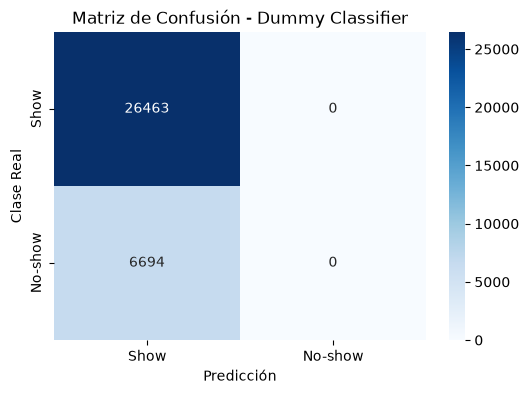

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Definir variables predictoras y objetivo
# Excluimos identificadores y fechas para este modelo base simple
columnas_excluir = ['PatientId', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood', 'No-show', 'AppointmentDayOfWeek']
X = df.drop(columns=[col for col in columnas_excluir if col in df.columns])
y = df['No-show']

# Convertir variables categóricas a numéricas (como 'Gender')
X = pd.get_dummies(X, drop_first=True)

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Inicializar y entrenar el Dummy Classifier (estrategia 'most_frequent')
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

# Predecir en el conjunto de prueba
y_pred = dummy_clf.predict(X_test)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

# Mostrar resultados
print("=== Métricas del Dummy Classifier (Most Frequent) ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}\n")

print("Matriz de Confusión:")
print(cm)

# Visualizar la matriz de confusión con Seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Show', 'No-show'],
            yticklabels=['Show', 'No-show'])
plt.title('Matriz de Confusión - Dummy Classifier')
plt.ylabel('Clase Real')
plt.xlabel('Predicción')
plt.show()

# Regresión logística

=== Métricas de la Regresión Logística ===
Accuracy:  0.6663
Precision: 0.3156
Recall:    0.5587
F1-score:  0.4034

Reporte de Clasificación:
              precision    recall  f1-score   support

       False       0.86      0.69      0.77     26463
        True       0.32      0.56      0.40      6694

    accuracy                           0.67     33157
   macro avg       0.59      0.63      0.59     33157
weighted avg       0.75      0.67      0.69     33157



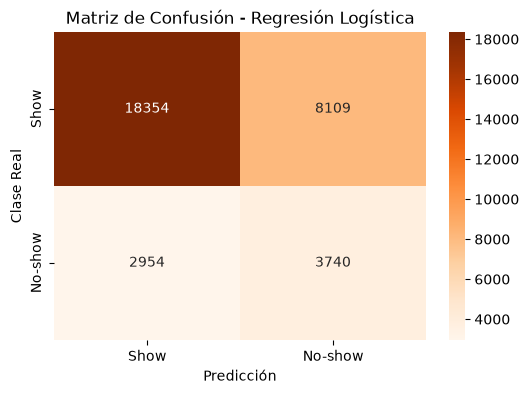

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Inicializar y entrenar el modelo de Regresión Logística
# Usamos max_iter=1000 para asegurar la convergencia del solver
log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
log_reg.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred_lr = log_reg.predict(X_test)

# Calcular métricas
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, zero_division=0)
recall_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Mostrar resultados
print("=== Métricas de la Regresión Logística ===")
print(f"Accuracy:  {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall:    {recall_lr:.4f}")
print(f"F1-score:  {f1_lr:.4f}\n")

print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Visualizar la matriz de confusión con Seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Show', 'No-show'],
            yticklabels=['Show', 'No-show'])
plt.title('Matriz de Confusión - Regresión Logística')
plt.ylabel('Clase Real')
plt.xlabel('Predicción')
plt.show()

#Resumen de Baseline


A continuación se presenta una comparación de los dos modelos iniciales implementados para predecir la inasistencia a las citas médicas (*No-show*):

| Métrica | Dummy Classifier (Most Frequent) | Regresión Logística (Class Weight: Balanced) |
| :--- | :---: | :---: |
| **Accuracy (Exactitud)** | 79.81% | 66.64% |
| **Precision (Precisión)** | 0.00% | 31.58% |
| **Recall (Sensibilidad)** | 0.00% | 55.90% |
| **F1-Score** | 0.00% | 40.36% |

### Conclusiones y Análisis:

1. **Dummy Classifier (Most Frequent):**
   * Al predecir siempre la clase mayoritaria (*Show* o asistencia, que representa ~80% de los datos), obtiene un **Accuracy del 79.81%**.
   * Sin embargo, este modelo es completamente inútil para el negocio, ya que su **Recall es 0.00%**; es decir, no es capaz de detectar a ningún paciente que faltará a su cita.

2. **Regresión Logística (Balanceada):**
   * Al incorporar el parámetro `class_weight="balanced"`, el modelo se ve forzado a prestar atención a la clase minoritaria (*No-show*).
   * Aunque la exactitud global baja al **66.64%**, la capacidad de detectar inasistencias reales sube significativamente, logrando un **Recall del 55.90%** (detecta más de la mitad de las ausencias reales).
   * La precisión para la clase *No-show* es baja (**31.58%**), lo que significa que tendremos un número considerable de falsos positivos (pacientes que el modelo dice que faltarán, pero que en realidad sí asistirán).
